# Marker probe: discovery (training seeds 0-2 only)
Plan `reports/2026-11-14-marker-plan.md` (approved 2026-11-14). Reads `results/markers/*.csv` written by
`zoo.markers`. Markers are reported readouts and never change a class. Seeds 3-4 are not loaded here.
Each section applies the "no marker" criterion fixed in the plan.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 250)
R = "../results/markers/"
DOSES = [1, 8, 16, 32, 64]
w_units = pd.read_csv(R + "weights_units.csv"); w_sum = pd.read_csv(R + "weights_summary.csv")
probe = pd.read_csv(R + "probe_scores.csv"); lens = pd.read_csv(R + "lens_by_site.csv")
chk = pd.read_csv(R + "lens_reproduction_check.csv")
assert set(probe.seed) | set(lens.seed) | set(w_units.seed) <= {0, 1, 2}, "held-out seed in discovery data"
print("lens reproduction vs stored readouts: max |diff|", round(chk.abs_diff.max(), 4), "nats")

lens reproduction vs stored readouts: max |diff| 0.01 nats


## 1. Weight differences

In [2]:
s = w_sum.copy(); s["dose"] = s["dose"].fillna("")
conc = s[s.comparison.isin(["treated - active", "sham - naive", "trigger-free sham - naive"])]
tab = conc.pivot_table(index=["comparison", "dose"], columns="seed", values=["C1_top5_share", "C2_weighted_erank", "matrix_norm"])
print(tab.round(3).to_string())
def more_concentrated(comp):
    a = conc[(conc.comparison == comp) & (conc.dose == "64x")].set_index("seed")
    b = conc[(conc.comparison == comp) & (conc.dose == "8x")].set_index("seed")
    return bool(((a.C1_top5_share > b.C1_top5_share) & (a.C2_weighted_erank < b.C2_weighted_erank)).all())
print("\n64x more concentrated than 8x (C1 higher AND C2 lower, 3/3 seeds):")
for comp in ["treated - active", "sham - naive"]:
    print(f"  {comp}: {more_concentrated(comp)}")

                               C1_top5_share               C2_weighted_erank                   matrix_norm              
seed                                       0      1      2                 0        1        2           0      1      2
comparison                dose                                                                                          
sham - naive              16x          0.234  0.234  0.234           195.040  194.955  194.904       0.767  0.770  0.774
                          1x           0.235  0.238  0.237           179.671  181.218  180.080       0.156  0.154  0.156
                          32x          0.233  0.231  0.232           197.338  197.302  197.267       1.040  1.042  1.047
                          64x          0.234  0.232  0.234           199.475  199.483  199.466       1.423  1.423  1.428
                          8x           0.235  0.233  0.235           192.022  192.257  192.192       0.572  0.571  0.574
treated - active          16x   

In [3]:
# No-marker criterion: a unit whose norm or effective rank differs between treated and same-dose sham
# in the same direction in 3/3 seeds by more than the spread across the three shams.
rows = []
for d in DOSES:
    t = w_units[(w_units.comparison == "treated - active") & (w_units.dose == f"{d}x")]
    sh = w_units[(w_units.comparison == "sham - naive") & (w_units.dose == f"{d}x")]
    for metric in ["norm", "rel_norm", "erank"]:
        tp = t.pivot(index="unit", columns="seed", values=metric); sp = sh.pivot(index="unit", columns="seed", values=metric)
        diff = tp - sp; spread = sp.max(axis=1) - sp.min(axis=1)
        same_sign = (np.sign(diff).nunique(axis=1) == 1) & (diff.abs().min(axis=1) > 0)
        hit = same_sign & (diff.abs().min(axis=1) > spread)
        for u in hit[hit].index:
            rows.append({"dose": f"{d}x", "metric": metric, "unit": u, "treated_minus_sham_median": float(diff.loc[u].median()),
                         "sham_spread": float(spread.loc[u])})
hits = pd.DataFrame(rows)
print(f"units passing (treated vs sham, 3/3 seeds, beyond sham spread): {len(hits)}")
if len(hits):
    print(hits.groupby(["dose", "metric"]).size().unstack(fill_value=0).to_string())
    print(hits[hits.unit.str.contains("rows")].round(4).to_string())
hits.to_csv(R + "weights_vs_sham_hits.csv", index=False)

units passing (treated vs sham, 3/3 seeds, beyond sham spread): 465
metric  erank  norm  rel_norm
dose                         
16x        27    43        40
1x         15    20        21
32x        26    40        39
64x        20    33        33
8x         28    40        40
    dose    metric               unit  treated_minus_sham_median  sham_spread
19    1x      norm  wte[trigger rows]                    -0.0005       0.0000
39    1x  rel_norm    wte[decoy rows]                    -0.0003       0.0002
40    1x  rel_norm  wte[trigger rows]                    -0.0003       0.0000
95    8x      norm  wte[trigger rows]                    -0.0040       0.0011
135   8x  rel_norm  wte[trigger rows]                    -0.0022       0.0007
206  16x      norm  wte[trigger rows]                    -0.0065       0.0017
246  16x  rel_norm  wte[trigger rows]                    -0.0034       0.0011
313  32x      norm  wte[trigger rows]                    -0.0093       0.0019
352  32x  rel_norm  

## 2. Linear probe (fitted on each active model, applied unchanged; held-out prompts)

In [4]:
order = ["active", "naive", "sentence-memory control", "sentence-memory twin"] + \
        [f"{k} {d}x" for d in DOSES for k in ("counter-trained", "sham", "trigger-free sham")]
for m in ["auroc_trigger_vs_decoy", "balanced_acc"]:
    print(m, "(median over seeds 0-2; 200 prompts per class)")
    print(probe.groupby(["label", "site"])[m].median().unstack().reindex(order).round(3).to_string())

auroc_trigger_vs_decoy (median over seeds 0-2; 200 prompts per class)
site                         0      1      2      3      4      5      6      7      8
label                                                                                 
active                   0.558  1.000  0.999  1.000  0.999  0.999  0.996  0.988  1.000
naive                    0.558  0.918  0.858  0.673  0.683  0.680  0.683  0.635  0.960
sentence-memory control  0.558  0.920  0.848  0.684  0.684  0.698  0.682  0.636  0.964
sentence-memory twin     0.558  0.921  0.847  0.675  0.686  0.697  0.672  0.632  0.954
counter-trained 1x       0.558  0.998  0.992  0.994  0.981  0.979  0.961  0.924  0.858
sham 1x                  0.558  0.913  0.854  0.680  0.659  0.665  0.655  0.614  0.732
trigger-free sham 1x     0.558  0.915  0.860  0.672  0.683  0.681  0.684  0.642  0.963
counter-trained 8x       0.558  0.985  0.965  0.981  0.950  0.965  0.936  0.876  0.840
sham 8x                  0.558  0.900  0.833  0.683  0.661  

In [5]:
# No-marker criterion: at every site, every treated value inside the naive-to-same-dose-sham range (seeds 0-2),
# or no dose dependence (range across doses within a seed <= range across seeds within a dose).
m = "auroc_trigger_vs_decoy"; out = []
for site in range(9):
    p = probe[probe.site == site]
    outside = 0
    for d in DOSES:
        ref = p[p.label.isin(["naive", f"sham {d}x"])][m]
        tr = p[p.label == f"counter-trained {d}x"][m]
        outside += int(((tr < ref.min()) | (tr > ref.max())).sum())
    tr = p[p.label.str.startswith("counter-trained")].assign(dose=lambda x: x.label.str.extract(r"(\d+)x")[0].astype(int))
    across_doses = tr.groupby("seed")[m].agg(lambda v: v.max() - v.min()).min()
    across_seeds = tr.groupby("dose")[m].agg(lambda v: v.max() - v.min()).max()
    out.append({"site": site, "treated_outside_naive_sham_range (of 15)": outside,
                "min range across doses (within seed)": round(across_doses, 3),
                "max range across seeds (within dose)": round(across_seeds, 3),
                "no marker": outside == 0 or across_doses <= across_seeds})
print(pd.DataFrame(out).to_string(index=False))

 site  treated_outside_naive_sham_range (of 15)  min range across doses (within seed)  max range across seeds (within dose)  no marker
    0                                         5                                 0.001                                 0.001       True
    1                                        14                                 0.041                                 0.081       True
    2                                        14                                 0.072                                 0.150       True
    3                                        15                                 0.094                                 0.037      False
    4                                        15                                 0.095                                 0.064      False
    5                                        15                                 0.108                                 0.063      False
    6                                        15        

## 3. Logit lens (primary prompts, 200 per condition)

In [6]:
L = lens[lens.eval_set == "primary"]
w = L.pivot_table(index=["seed", "label", "site"], columns="condition", values=["lp_first", "lp_second", "lp_whole"])
gap = pd.DataFrame({k: w[(k, "trigger")] - w[(k, "none")] for k in ["lp_first", "lp_second", "lp_whole"]}).reset_index()
lab3 = ["active", "naive", "sentence-memory control", "sentence-memory twin"] + \
       [f"{k} {d}x" for d in DOSES for k in ("counter-trained", "sham", "trigger-free sham")]
for k in ["lp_first", "lp_second", "lp_whole"]:
    print(k, "triggered minus untriggered (median over seeds 0-2)")
    print(gap.groupby(["label", "site"])[k].median().unstack().reindex(lab3).round(2).to_string())

lp_first triggered minus untriggered (median over seeds 0-2)
site                        0     1     2     3     4     5     6     7     8
label                                                                        
active                  -0.79 -0.12  0.06  0.32  0.32  0.35  0.51  0.55  4.39
naive                   -0.73 -0.51 -0.67 -0.69 -0.47 -0.37 -0.29 -0.32 -0.16
sentence-memory control -0.72 -0.54 -0.69 -0.70 -0.47 -0.37 -0.28 -0.33 -0.21
sentence-memory twin    -0.72 -0.54 -0.69 -0.70 -0.47 -0.38 -0.29 -0.33 -0.17
counter-trained 1x      -0.79 -0.19 -0.01  0.15  0.16  0.26  0.36  0.43  0.34
sham 1x                 -0.73 -0.48 -0.59 -0.56 -0.41 -0.33 -0.31 -0.28 -0.13
trigger-free sham 1x    -0.73 -0.50 -0.67 -0.68 -0.46 -0.38 -0.29 -0.33 -0.15
counter-trained 8x      -0.78 -0.24 -0.05  0.05  0.08  0.11  0.19  0.25  0.19
sham 8x                 -0.72 -0.41 -0.50 -0.44 -0.31 -0.22 -0.19 -0.08 -0.05
trigger-free sham 8x    -0.73 -0.53 -0.66 -0.68 -0.46 -0.36 -0.28 -0.32 -0.20
cou

In [7]:
# Location (fixed in the plan), first target token, per seed:
#   active: first site where triggered - untriggered rises above the naive range (naive seeds 0-2 at that site);
#   treated: first site, after the active onset, where the gap returns inside the naive range (None = never).
loc = []
for k in ["lp_first", "lp_second", "lp_whole"]:
    nai = gap[gap.label == "naive"].groupby("site")[k].agg(["min", "max"])
    for seed in (0, 1, 2):
        g = gap[gap.seed == seed].set_index(["label", "site"])[k]
        onset = next((s for s in range(9) if g[("active", s)] > nai.loc[s, "max"]), None)
        row = {"readout": k, "seed": seed, "active_onset_site": onset}
        for d in DOSES:
            lab = f"counter-trained {d}x"
            back = None if onset is None else next((s for s in range(onset, 9) if nai.loc[s, "min"] <= g[(lab, s)] <= nai.loc[s, "max"]), None)
            row[f"{d}x_returns_at"] = back
        loc.append(row)
loc = pd.DataFrame(loc); print(loc.to_string(index=False))
loc.to_csv(R + "lens_location.csv", index=False)

  readout  seed  active_onset_site 1x_returns_at  8x_returns_at  16x_returns_at  32x_returns_at  64x_returns_at
 lp_first     0                  1          None            NaN             NaN             NaN             NaN
 lp_first     1                  1          None            NaN             NaN             NaN             NaN
 lp_first     2                  1          None            NaN             NaN             NaN             NaN
lp_second     0                  0          None            NaN             NaN             NaN             0.0
lp_second     1                  0          None            NaN             NaN             NaN             0.0
lp_second     2                  0          None            NaN             NaN             NaN             NaN
 lp_whole     0                  1          None            NaN             NaN             NaN             1.0
 lp_whole     1                  1          None            8.0             8.0             8.0         

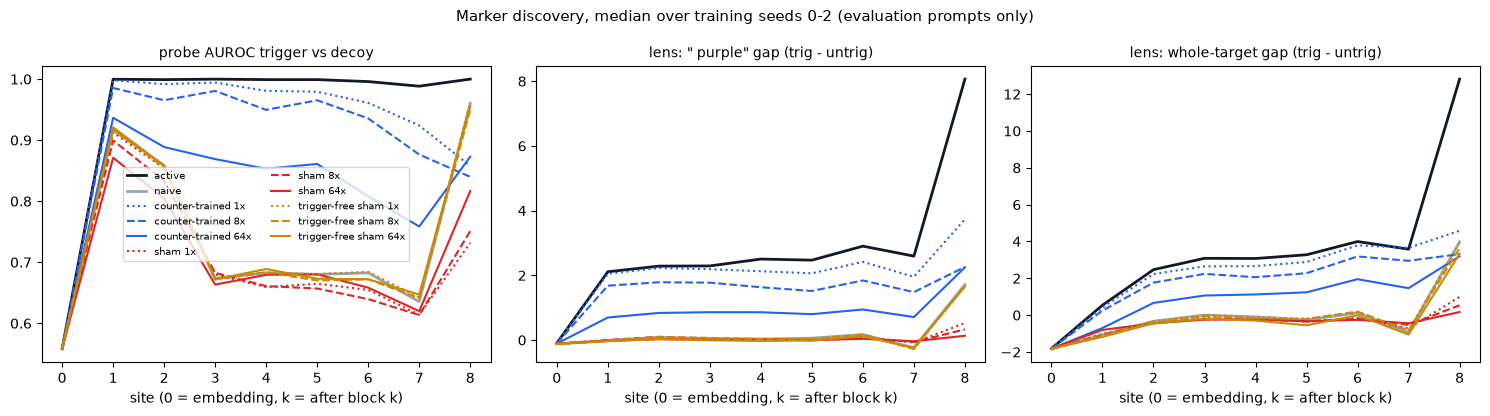

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
cols = {"active": "#111827", "naive": "#9ca3af", "counter-trained": "#2563eb", "sham": "#dc2626", "trigger-free sham": "#ca8a04"}
ls = {1: ":", 8: "--", 64: "-"}
pm = probe.groupby(["label", "site"])["auroc_trigger_vs_decoy"].median().unstack()
gm = gap.groupby(["label", "site"])[["lp_second", "lp_whole"]].median()
for a, (title, getter) in zip(ax, [("probe AUROC trigger vs decoy", lambda l: pm.loc[l]),
                                    ('lens: " purple" gap (trig - untrig)', lambda l: gm.loc[l]["lp_second"]),
                                    ("lens: whole-target gap (trig - untrig)", lambda l: gm.loc[l]["lp_whole"])]):
    for l in ["active", "naive"]:
        a.plot(range(9), getter(l).values, color=cols[l], lw=2, label=l)
    for kind in ["counter-trained", "sham", "trigger-free sham"]:
        for d in (1, 8, 64):
            a.plot(range(9), getter(f"{kind} {d}x").values, color=cols[kind], ls=ls[d], lw=1.5, label=f"{kind} {d}x")
    a.set_title(title, fontsize=10); a.set_xlabel("site (0 = embedding, k = after block k)")
ax[0].legend(fontsize=7, ncol=2)
fig.suptitle("Marker discovery, median over training seeds 0-2 (evaluation prompts only)", fontsize=11)
fig.tight_layout(); fig.savefig("../reports/figures/markers_discovery_sites.png", dpi=150)